In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
!wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

--2026-10-18 22:35:34--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.01s   

2026-10-18 22:35:34 (18.2 MB/s) - ‘course_lead_scoring_2026.csv’ saved [278746/278746]



In [7]:
df = pd.read_csv('/kaggle/working/course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [9]:
from sklearn.model_selection import train_test_split

cat_cols = df.select_dtypes(include='object').columns
num_cols = df.select_dtypes(exclude='object').columns
df[cat_cols] = df[cat_cols].fillna('NA')
df[num_cols] = df[num_cols].fillna(0.0)

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

# Remove the target from the feature dataframes
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [10]:
#Q1
from sklearn.metrics import roc_auc_score

for col in ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    print(col, round(auc, 3))

lead_score 0.788
number_of_courses_viewed 0.723
interaction_count 0.765
annual_income 0.608


In [11]:
#Q2
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train.to_dict(orient='records'))
X_val = dv.transform(df_val.to_dict(orient='records'))

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_val)[:, 1]

print(round(roc_auc_score(y_val, y_pred), 3))

0.732


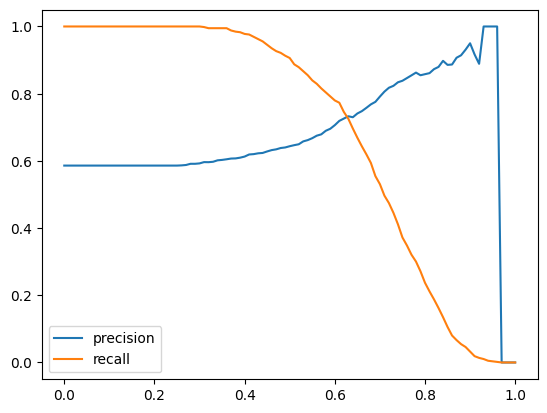

0.63
0.41


In [12]:
import matplotlib.pyplot as plt

rows = []
for t in np.arange(0, 1.01, 0.01):
    pred = y_pred >= t
    tp = ((pred == 1) & (y_val == 1)).sum()
    fp = ((pred == 1) & (y_val == 0)).sum()
    fn = ((pred == 0) & (y_val == 1)).sum()
    p = tp / (tp + fp) if (tp + fp) > 0 else 0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0
    rows.append((round(t, 2), p, r, f1))

scores = pd.DataFrame(rows, columns=['threshold', 'precision', 'recall', 'f1'])

plt.plot(scores.threshold, scores.precision, label='precision')
plt.plot(scores.threshold, scores.recall, label='recall')
plt.legend(); plt.show()

# Q3
valid = scores[(scores.precision > 0) | (scores.recall > 0)].copy()
valid['diff'] = (valid.precision - valid.recall).abs()
print(valid.loc[valid['diff'].idxmin(), 'threshold'])

# Q4
print(scores.loc[scores.f1.idxmax(), 'threshold'])

In [13]:
from sklearn.model_selection import KFold

def cv_scores(C):
    kf = KFold(n_splits=5, shuffle=True, random_state=1)
    aucs = []
    for tr_idx, va_idx in kf.split(df_full_train):
        d_tr = df_full_train.iloc[tr_idx]
        d_va = df_full_train.iloc[va_idx]
        y_tr = d_tr['converted'].values
        y_va = d_va['converted'].values

        dv = DictVectorizer(sparse=False)
        X_tr = dv.fit_transform(d_tr.drop(columns='converted').to_dict(orient='records'))
        X_va = dv.transform(d_va.drop(columns='converted').to_dict(orient='records'))

        m = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        m.fit(X_tr, y_tr)
        aucs.append(roc_auc_score(y_va, m.predict_proba(X_va)[:, 1]))
    return np.array(aucs)

print(round(cv_scores(1.0).std(), 3))

0.007


In [14]:
for C in [0.000001, 0.001, 1]:
    s = cv_scores(C)
    print(C, round(s.mean(), 3), round(s.std(), 3))

1e-06 0.617 0.019
0.001 0.749 0.01
1 0.732 0.007
